# Lista de Exercícios 03
## Splines Cúbicos

**Programa:** PPGMC / UESC  
**Base:** Burden & Faires — Capítulo 3

---

## Objetivos

- Implementar o algoritmo de spline cúbico natural
- Analisar propriedades de suavidade
- Comparar com interpolação global
- Discutir estabilidade numérica

---

## Pseudocódigo — Spline Cúbico Natural

(Adaptado de Burden & Faires)

Para construir o interpolador spline cúbico $S$ para a função $f$, definida nos números $x_0 < x_1 < \dots < x_n$ , e satisfazendo $S''(x_0) = S''(x_n) = 0$ (spline cúbico natural):

INPUT: $n;\, x_0, x_1, \dots, x_n; \, a_0 = f(x_0), a_1 = f(x_1), \dots, a_n = f(x(n)$

OUTPUT: $a_j, b_j, c_j, d_j$ para $j=0,1,\dots,n-1$ 

1. Para $i=0,1,\dots,n-1$, fazer $h_i = x_{i+1} - x_i$

2. Para $i=1,2,\dots,n-1$, fazer

$$ \alpha_i = \frac{3}{h_i}(a_{i+1}-a_i) - \frac{3}{h_{i-1}}(a_i-a_{i-1})$$

3. Inicialização: $l_0=1, \mu_0=0, z_0=0$

4. Para $i=1,2,\dots,n-1$, fazer

   $$ l_i=2(x_{i+1}-x_{i-1}) - h_{i-1}\mu_{i-1} $$
   $$ \mu _i=\frac{h_i}{l_i} $$
   $$ z_i=\frac{(\alpha_i-h_{i-1}z_{i-1})}{l_i} $$

5. Condições finais: $l_n=1, z_n=0, c_n=0$

6. Para $j=n-1, n-2, \dots, 0$ fazer:
   
   $$ c_j=z_j-\mu_j*c_{j+1} $$
   $$ b_j=\frac{(a_{j+1}-a_j)}{h_j} - \frac{h_j(c_{j+1}+2c_j)}{3} $$
   $$ d_j=\frac{(c_{j+1}-c_j)}{(3h_j)} $$

7. OUTPUT: $a_j, b_j, c_j, d_j$ para $j=0,1,\dots,n-1$ 

---

## Observação

Você pode utilizar implementações como `scipy.interpolate.CubicSpline`
apenas para validar resultados, mas NÃO para resolver os exercícios.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def cubic_spline_natural(x, a):
    n = len(x) - 1
    
    # Passo 1
    h = np.zeros(n)
    for i in range(n):
        h[i] = x[i+1] - x[i]
        
    # Passo 2
    alpha = np.zeros(n)
    for i in range(1, n):
        termo1 = (3.0 / h[i]) * (a[i+1] - a[i])
        termo2 = (3.0 / h[i-1]) * (a[i] - a[i-1])
        alpha[i] = termo1 - termo2
        
    # Passo 3 (Inicialização)
    l = np.zeros(n+1)
    mu = np.zeros(n+1)
    z = np.zeros(n+1)
    
    l[0] = 1.0
    mu[0] = 0.0
    z[0] = 0.0
    
    # Passo 4
    for i in range(1, n):
        l[i] = 2.0 * (x[i+1] - x[i-1]) - h[i-1] * mu[i-1]
        mu[i] = h[i] / l[i]
        z[i] = (alpha[i] - h[i-1] * z[i-1]) / l[i]
        
    # Passo 5 (Condições finais)
    l[n] = 1.0
    z[n] = 0.0
    c = np.zeros(n+1)
    c[n] = 0.0
    
    # Passo 6
    b = np.zeros(n)
    d = np.zeros(n)
    
    for j in range(n-1, -1, -1):
        c[j] = z[j] - mu[j] * c[j+1]
        b[j] = (a[j+1] - a[j]) / h[j] - h[j] * (c[j+1] + 2.0 * c[j]) / 3.0
        d[j] = (c[j+1] - c[j]) / (3.0 * h[j])
        
    # Passo 7 (OUTPUT)
    return a[:-1], b, c[:-1], d

def evaluate_spline(x_eval, x, a, b, c, d):
    y_eval = np.zeros_like(x_eval)
    for k, xv in enumerate(x_eval):
        j = np.searchsorted(x, xv) - 1
        if j < 0: j = 0
        if j >= len(x) - 1: j = len(x) - 2
        dx = xv - x[j]
        y_eval[k] = a[j] + b[j]*dx + c[j]*(dx**2) + d[j]*(dx**3)
    return y_eval

In [3]:
def lagrange_basis(x, xs, i):
    L = 1.0
    for j in range(len(xs)):
        if j != i:
            L *= (x - xs[j]) / (xs[i] - xs[j])
    return L

def lagrange_interp(x, xs, ys):
    total = 0.0
    for i in range(len(xs)):
        total += ys[i] * lagrange_basis(x, xs, i)
    return total

## Exercício 1.

Implemente o spline cúbico natural para um conjunto simples de 5 pontos gerados por você mesmo.

Mostre:
- coeficientes
- gráfico do spline

--- Coeficientes do Spline Cúbico Natural ---
Intervalo [0.0, 1.0]:
S_0(x) = 2.0000 + -1.8036(x-0.0) + 0.0000(x-0.0)^2 + 0.8036(x-0.0)^3

Intervalo [1.0, 2.0]:
S_1(x) = 1.0000 + 0.6071(x-1.0) + 2.4107(x-1.0)^2 + -2.0179(x-1.0)^3

Intervalo [2.0, 3.0]:
S_2(x) = 2.0000 + -0.6250(x-2.0) + -3.6429(x-2.0)^2 + 2.2679(x-2.0)^3

Intervalo [3.0, 4.0]:
S_3(x) = 0.0000 + -1.1071(x-3.0) + 3.1607(x-3.0)^2 + -1.0536(x-3.0)^3



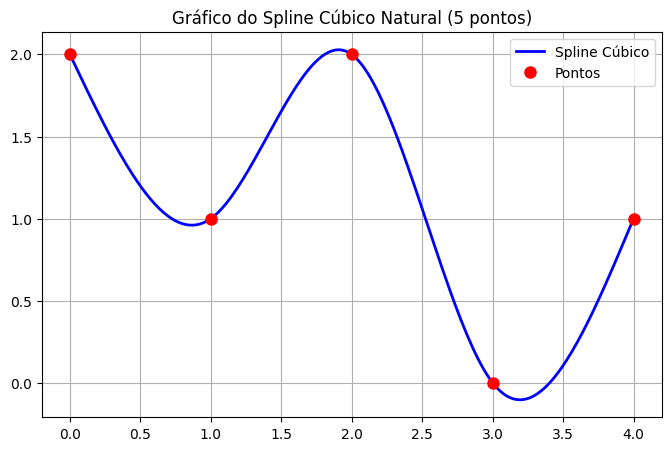

In [4]:
x_dados = np.array([0.0, 1.0, 2.0, 3.0, 4.0])
y_dados = np.array([2.0, 1.0, 2.0, 0.0, 1.0])

a, b, c, d = cubic_spline_natural(x_dados, y_dados)

print("--- Coeficientes do Spline Cúbico Natural ---")
for j in range(len(a)):
    print(f"Intervalo [{x_dados[j]}, {x_dados[j+1]}]:")
    print(f"S_{j}(x) = {a[j]:.4f} + {b[j]:.4f}(x-{x_dados[j]}) + {c[j]:.4f}(x-{x_dados[j]})^2 + {d[j]:.4f}(x-{x_dados[j]})^3\n")

x_plot = np.linspace(x_dados[0], x_dados[-1], 200)
y_plot = evaluate_spline(x_plot, x_dados, a, b, c, d)

plt.figure(figsize=(8, 5))
plt.plot(x_plot, y_plot, 'b-', linewidth=2, label='Spline Cúbico')
plt.plot(x_dados, y_dados, 'ro', markersize=8, label='Pontos')
plt.title('Gráfico do Spline Cúbico Natural (5 pontos)')
plt.legend()
plt.grid(True)
plt.show()

## Exercício 2.

Implemente o spline cúbico natural para um conjunto simples de pontos gerados utilizando a função $\sin(x)$ no intervalo entre $0 \leq x \leq \pi$. 

Mostre:
- coeficientes
- gráfico do spline

--- Coeficientes do Spline Cúbico Natural para sin(x) ---
Intervalo [0.0000, 0.7854]:
S_0(x) = 0.0000 + 0.9977(x-0.0000) + 0.0000(x-0.0000)^2 + -0.1579(x-0.0000)^3

Intervalo [0.7854, 1.5708]:
S_1(x) = 0.7071 + 0.7055(x-0.7854) + -0.3721(x-0.7854)^2 + -0.0654(x-0.7854)^3

Intervalo [1.5708, 2.3562]:
S_2(x) = 1.0000 + 0.0000(x-1.5708) + -0.5262(x-1.5708)^2 + 0.0654(x-1.5708)^3

Intervalo [2.3562, 3.1416]:
S_3(x) = 0.7071 + -0.7055(x-2.3562) + -0.3721(x-2.3562)^2 + 0.1579(x-2.3562)^3



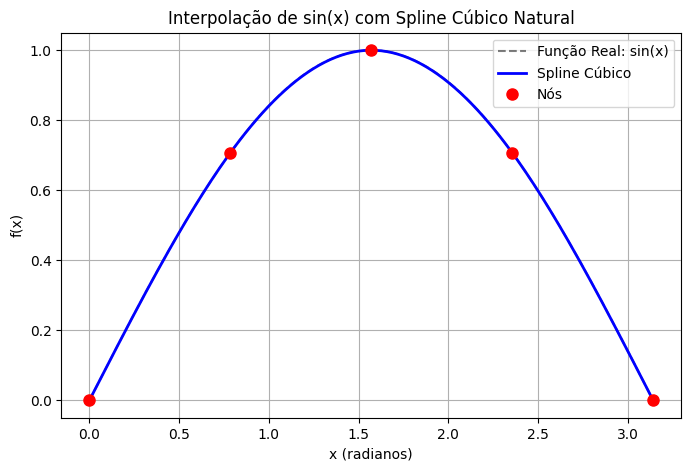

In [5]:
x_dados = np.linspace(0, np.pi, 5)
y_dados = np.sin(x_dados)

a, b, c, d = cubic_spline_natural(x_dados, y_dados)

print("--- Coeficientes do Spline Cúbico Natural para sin(x) ---")
for j in range(len(a)):
    print(f"Intervalo [{x_dados[j]:.4f}, {x_dados[j+1]:.4f}]:")
    print(f"S_{j}(x) = {a[j]:.4f} + {b[j]:.4f}(x-{x_dados[j]:.4f}) + {c[j]:.4f}(x-{x_dados[j]:.4f})^2 + {d[j]:.4f}(x-{x_dados[j]:.4f})^3\n")

x_plot = np.linspace(0, np.pi, 200)
y_spline = evaluate_spline(x_plot, x_dados, a, b, c, d)
y_real = np.sin(x_plot)

plt.figure(figsize=(8, 5))
plt.plot(x_plot, y_real, 'k--', alpha=0.5, label='Função Real: sin(x)')
plt.plot(x_plot, y_spline, 'b-', linewidth=2, label='Spline Cúbico')
plt.plot(x_dados, y_dados, 'ro', markersize=8, label='Nós')

plt.title('Interpolação de sin(x) com Spline Cúbico Natural')
plt.xlabel('x (radianos)')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()

## Exercício 3.

Implemente o spline cúbico natural para um conjunto simples de pontos gerados utilizando a função $e^x$ para $-1 \leq x \leq 1$.

Mostre:
- coeficientes
- gráfico do spline

--- Coeficientes do Spline Cúbico Natural para e^x ---
Intervalo [-1.0000, -0.5000]:
S_0(x) = 0.3679 + 0.4158(x - (-1.0000)) + 0.0000(x - (-1.0000))^2 + 0.2460(x - (-1.0000))^3

Intervalo [-0.5000, 0.0000]:
S_1(x) = 0.6065 + 0.6003(x - (-0.5000)) + 0.3690(x - (-0.5000))^2 + 0.0085(x - (-0.5000))^3

Intervalo [0.0000, 0.5000]:
S_2(x) = 1.0000 + 0.9757(x - (0.0000)) + 0.3817(x - (0.0000))^2 + 0.5236(x - (0.0000))^3

Intervalo [0.5000, 1.0000]:
S_3(x) = 1.6487 + 1.7501(x - (0.5000)) + 1.1671(x - (0.5000))^2 + -0.7781(x - (0.5000))^3



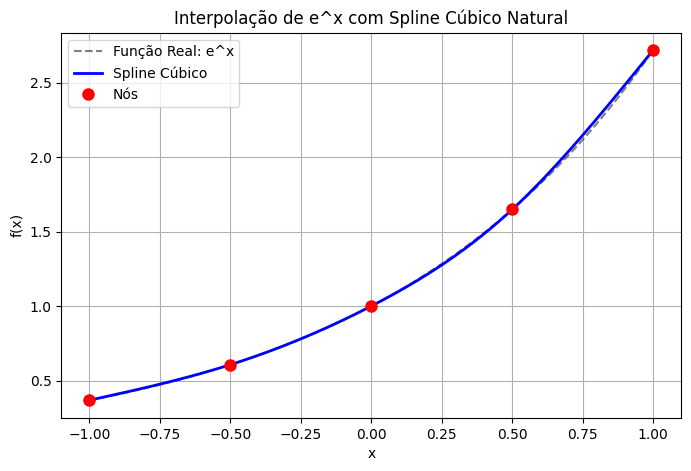

In [6]:
x_dados = np.linspace(-1, 1, 5)
y_dados = np.exp(x_dados)

a, b, c, d = cubic_spline_natural(x_dados, y_dados)

print("--- Coeficientes do Spline Cúbico Natural para e^x ---")
for j in range(len(a)):
    print(f"Intervalo [{x_dados[j]:.4f}, {x_dados[j+1]:.4f}]:")
    print(f"S_{j}(x) = {a[j]:.4f} + {b[j]:.4f}(x - ({x_dados[j]:.4f})) + {c[j]:.4f}(x - ({x_dados[j]:.4f}))^2 + {d[j]:.4f}(x - ({x_dados[j]:.4f}))^3\n")

x_plot = np.linspace(-1, 1, 200)
y_spline = evaluate_spline(x_plot, x_dados, a, b, c, d)
y_real = np.exp(x_plot)

plt.figure(figsize=(8, 5))
plt.plot(x_plot, y_real, 'k--', alpha=0.5, label='Função Real: e^x')
plt.plot(x_plot, y_spline, 'b-', linewidth=2, label='Spline Cúbico')
plt.plot(x_dados, y_dados, 'ro', markersize=8, label='Nós')

plt.title('Interpolação de e^x com Spline Cúbico Natural')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()


## Exercício 4.

Implemente o spline cúbico natural para um conjunto simples de pontos.

Mostre:
- coeficientes
- gráfico do spline

--- Coeficientes do Spline Cúbico Natural ---
Intervalo [0.0, 1.0]:
S_0(x) = 0.0000 + 1.7143(x - 0.0) + 0.0000(x - 0.0)^2 + -0.7143(x - 0.0)^3

Intervalo [1.0, 2.0]:
S_1(x) = 1.0000 + -0.4286(x - 1.0) + -2.1429(x - 1.0)^2 + 1.5714(x - 1.0)^3

Intervalo [2.0, 3.0]:
S_2(x) = 0.0000 + 0.0000(x - 2.0) + 2.5714(x - 2.0)^2 + -1.5714(x - 2.0)^3

Intervalo [3.0, 4.0]:
S_3(x) = 1.0000 + 0.4286(x - 3.0) + -2.1429(x - 3.0)^2 + 0.7143(x - 3.0)^3



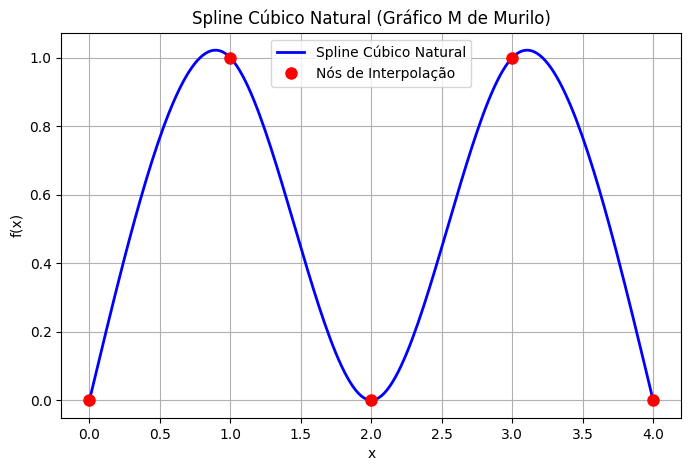

In [7]:
x_dados = np.array([0.0, 1.0, 2.0, 3.0, 4.0])
y_dados = np.array([0.0, 1.0, 0.0, 1.0, 0.0])

a, b, c, d = cubic_spline_natural(x_dados, y_dados)

print("--- Coeficientes do Spline Cúbico Natural ---")
for j in range(len(a)):
    print(f"Intervalo [{x_dados[j]:.1f}, {x_dados[j+1]:.1f}]:")
    print(f"S_{j}(x) = {a[j]:.4f} + {b[j]:.4f}(x - {x_dados[j]:.1f}) + {c[j]:.4f}(x - {x_dados[j]:.1f})^2 + {d[j]:.4f}(x - {x_dados[j]:.1f})^3\n")

x_plot = np.linspace(x_dados[0], x_dados[-1], 200)
y_spline = evaluate_spline(x_plot, x_dados, a, b, c, d)

plt.figure(figsize=(8, 5))
plt.plot(x_plot, y_spline, 'b-', linewidth=2, label='Spline Cúbico Natural')
plt.plot(x_dados, y_dados, 'ro', markersize=8, label='Nós de Interpolação')

plt.title('Spline Cúbico Natural (Gráfico M de Murilo)')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()


## Exercício 5.

Compare spline com interpolação polinomial global.
Use função de Runge.

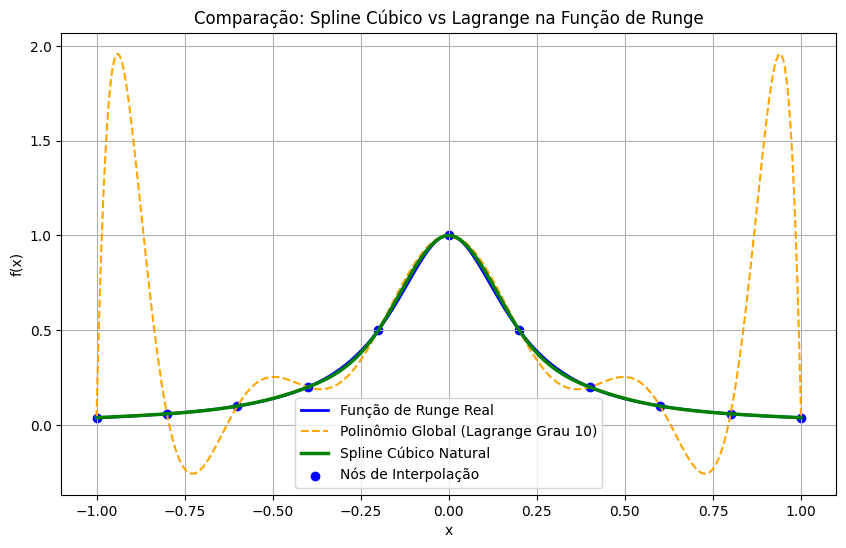

In [8]:
def evaluate_lagrange_array(x_eval, xs, ys):
    return np.array([lagrange_interp(xi, xs, ys) for xi in x_eval])

def runge_function(x):
    return 1 / (1 + 25*x**2)

x_dados = np.linspace(-1, 1, 11)
y_dados = runge_function(x_dados)

a, b, c, d = cubic_spline_natural(x_dados, y_dados)

x_plot = np.linspace(-1, 1, 400)
y_real = runge_function(x_plot)
y_lagrange = evaluate_lagrange_array(x_plot, x_dados, y_dados)
y_spline = evaluate_spline(x_plot, x_dados, a, b, c, d)

plt.figure(figsize=(10, 6))

plt.plot(x_plot, y_real, color= "blue", linestyle ="-", linewidth=2, label='Função de Runge Real')
plt.plot(x_plot, y_lagrange, color= "orange", linestyle ="--", linewidth=1.5, label='Polinômio Global (Lagrange Grau 10)')
plt.plot(x_plot, y_spline, color= "green", linestyle ="-", linewidth=2.5, label='Spline Cúbico Natural')
plt.scatter(x_dados, y_dados, color="blue", label='Nós de Interpolação')

plt.title('Comparação: Spline Cúbico vs Lagrange na Função de Runge')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()


O Spline Cúbico Natural ajuste foi excelente, ficando praticamente idêntico à Função de Runge. Já a Interpolação Polinomial Global Apresentou o famoso Fenômeno de Runge.

## Exercício 6.

Adicione pequenas perturbações nos dados e analise estabilidade.

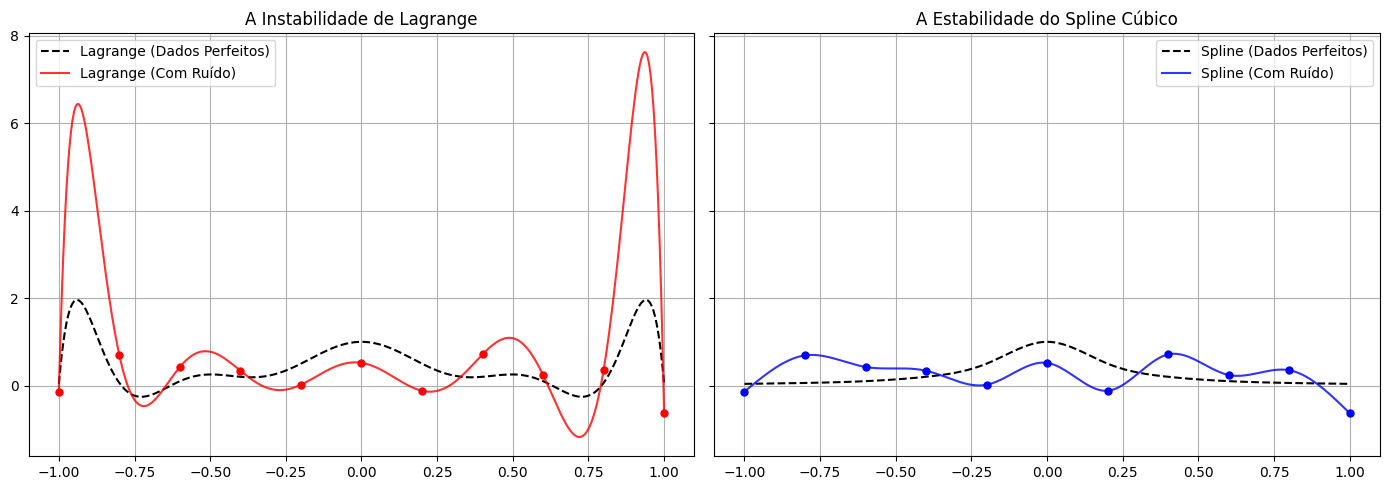

In [9]:
np.random.seed(42) 

x_dados = np.linspace(-1, 1, 11)
y_real = 1 / (1 + 25*x_dados**2)

ruido = np.random.uniform(-0.7, 0.7, size=len(x_dados))
y_perturbado = y_real + ruido

a_r, b_r, c_r, d_r = cubic_spline_natural(x_dados, y_real)
a_p, b_p, c_p, d_p = cubic_spline_natural(x_dados, y_perturbado)

x_plot = np.linspace(-1, 1, 400)

y_lagrange_real = np.array([lagrange_interp(xi, x_dados, y_real) for xi in x_plot])
y_lagrange_pert = np.array([lagrange_interp(xi, x_dados, y_perturbado) for xi in x_plot])

y_spline_real = evaluate_spline(x_plot, x_dados, a_r, b_r, c_r, d_r)
y_spline_pert = evaluate_spline(x_plot, x_dados, a_p, b_p, c_p, d_p)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

ax1.plot(x_plot, y_lagrange_real, 'k--', label='Lagrange (Dados Perfeitos)')
ax1.plot(x_plot, y_lagrange_pert, 'r-', alpha=0.8, label='Lagrange (Com Ruído)')
ax1.plot(x_dados, y_perturbado, 'ro', markersize=5)
ax1.set_title('A Instabilidade de Lagrange')
ax1.grid(True)
ax1.legend()

ax2.plot(x_plot, y_spline_real, 'k--', label='Spline (Dados Perfeitos)')
ax2.plot(x_plot, y_spline_pert, 'b-', alpha=0.8, label='Spline (Com Ruído)')
ax2.plot(x_dados, y_perturbado, 'bo', markersize=5)
ax2.set_title('A Estabilidade do Spline Cúbico')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()


A interpolação de Lagrange apresentou alta instabilidade. Por ser um polinômio único de grau elevado, o erro em um ponto afeta a curva inteira, causando oscilações descontroladas, principalmente nas extremidades do gráfico (pontas).

O Spline Cúbico mostrou-se muito mais estável. Como a interpolação é feita por pequenos trechos, o erro de um ponto fica isolado na região onde ele ocorreu. A curva se ajusta aos pontos ruidosos sem criar distorções anormais ou oscilações explosivas nas bordas.

## Exercício 7.

Compare spline com interpolação linear por partes. Utilize o conjunto de pontos do Exercício 2. 

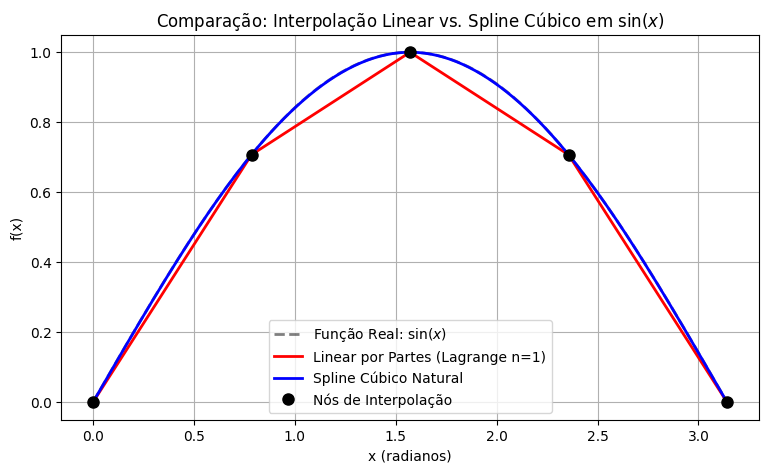

In [10]:
def piecewise_linear_lagrange(x_eval, x_nos, y_nos):
    y_eval = np.zeros_like(x_eval)
    for k, xv in enumerate(x_eval):
        j = np.searchsorted(x_nos, xv) - 1
        if j < 0: j = 0
        if j >= len(x_nos) - 1: j = len(x_nos) - 2
        
        x_trecho = x_nos[j:j+2]
        y_trecho = y_nos[j:j+2]
        y_eval[k] = lagrange_interp(xv, x_trecho, y_trecho)
    return y_eval

x_dados = np.linspace(0, np.pi, 5)
y_dados = np.sin(x_dados)

x_plot = np.linspace(0, np.pi, 200)

y_linear = piecewise_linear_lagrange(x_plot, x_dados, y_dados)

a, b, c, d = cubic_spline_natural(x_dados, y_dados)
y_spline = evaluate_spline(x_plot, x_dados, a, b, c, d)

y_real = np.sin(x_plot)

plt.figure(figsize=(9, 5))

plt.plot(x_plot, y_real, 'k--', alpha=0.5, linewidth=2, label='Função Real: $\sin(x)$')
plt.plot(x_plot, y_linear, 'r-', linewidth=2, label='Linear por Partes (Lagrange n=1)')
plt.plot(x_plot, y_spline, 'b-', linewidth=2, label='Spline Cúbico Natural')

plt.plot(x_dados, y_dados, 'ko', markersize=8, label='Nós de Interpolação')

plt.title('Comparação: Interpolação Linear vs. Spline Cúbico em $\sin(x)$')
plt.xlabel('x (radianos)')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()


**Interpolação Linear por Partes** Este método liga os pontos com retas. Por isso, a curva apresenta "quinas" nos nós, já que a inclinação muda bruscamente de um trecho para o outro. Com poucos pontos, o resultado parece um polígono e não consegue acompanhar bem a curvatura do seno, gerando um erro maior.

**Spline Cúbico Natural** O spline garante que a curva seja suave em todos os pontos. Além de passar pelos nós, ele força as inclinações e a curvatura a serem iguais onde os trechos se encontram. Isso elimina as quinas e faz com que, mesmo com apenas 5 pontos, a curva seja quase idêntica à função seno real.

## Exercício 8.

Analíse a implementação do algoritmo do spline cúbico natural feita com base no slgoritmo discutido em sala de aula.

Discuta:
- custo computacional: Compare a complexidade de tempo com a interpolação global utilizando 4, 8 e 16 pontos de interpolção 
- estabilidade: Compare o resultado de introduzir pequenas perturbações nos seus dados em relação à interpolação global. 

 EXPERIMENTO 1: COMPLEXIDADE DE TEMPO
N =  4 nós | Lagrange:     5.24 ms | Spline:  3.10 ms
N =  8 nós | Lagrange:    15.72 ms | Spline:  1.89 ms
N = 16 nós | Lagrange:    72.03 ms | Spline:  1.98 ms

 EXPERIMENTO 2: ESTABILIDADE (EFEITO CHICOTE)
 Inserindo erro de +0.5 apenas no nó central
Erro original inserido nos dados: 0.500
Dano máximo causado na curva de Lagrange: 8.825
Dano máximo causado na curva do Spline:   0.500


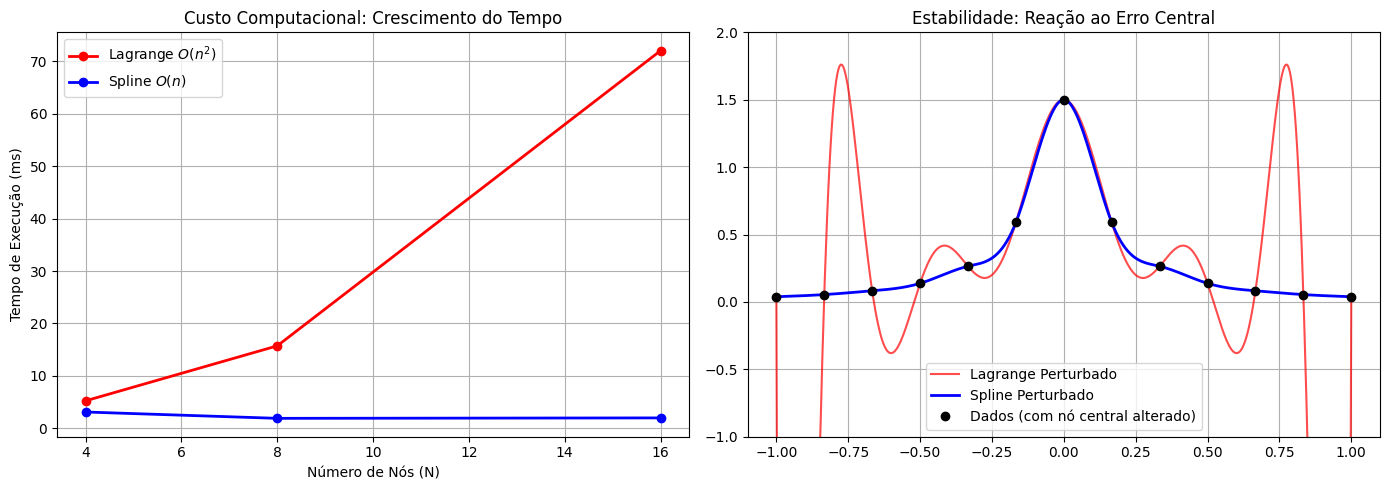

In [11]:
import time

print("="*50)
print(" EXPERIMENTO 1: COMPLEXIDADE DE TEMPO")
print("="*50)

n_pontos_lista = [4, 8, 16]
tempos_lagrange = []
tempos_spline = []

for n in n_pontos_lista:
    xs = np.linspace(-1, 1, n)
    ys = 1 / (1 + 25*xs**2)
    x_eval = np.linspace(-1, 1, 500)
    
    # Teste Lagrange
    start = time.perf_counter()
    y_lag = evaluate_lagrange_array(x_eval, xs, ys)
    tempo_lag = (time.perf_counter() - start) * 1000 
    tempos_lagrange.append(tempo_lag)
    
    # Teste Spline
    start = time.perf_counter()
    a, b, c, d = cubic_spline_natural(xs, ys) 
    y_spl = evaluate_spline(x_eval, xs, a, b, c, d)
    tempo_spl = (time.perf_counter() - start) * 1000 
    tempos_spline.append(tempo_spl)
    
    print(f"N = {n:2d} nós | Lagrange: {tempo_lag:8.2f} ms | Spline: {tempo_spl:5.2f} ms")

print("\n" + "="*50)
print(" EXPERIMENTO 2: ESTABILIDADE (EFEITO CHICOTE)")
print(" Inserindo erro de +0.5 apenas no nó central")
print("="*50)

N_estabilidade = 13
xs = np.linspace(-1, 1, N_estabilidade)
ys_puro = 1 / (1 + 25*xs**2)

ys_perturbado = ys_puro.copy()
indice_meio = N_estabilidade // 2
ys_perturbado[indice_meio] += 0.5 

x_eval = np.linspace(-1, 1, 500)

y_lag_puro = evaluate_lagrange_array(x_eval, xs, ys_puro)
a, b, c, d = cubic_spline_natural(xs, ys_puro)
y_spl_puro = evaluate_spline(x_eval, xs, a, b, c, d)

y_lag_pert = evaluate_lagrange_array(x_eval, xs, ys_perturbado)
a_p, b_p, c_p, d_p = cubic_spline_natural(xs, ys_perturbado)
y_spl_pert = evaluate_spline(x_eval, xs, a_p, b_p, c_p, d_p)

erro_max_lagrange = np.max(np.abs(y_lag_puro - y_lag_pert))
erro_max_spline = np.max(np.abs(y_spl_puro - y_spl_pert))

print(f"Erro original inserido nos dados: 0.500")
print(f"Dano máximo causado na curva de Lagrange: {erro_max_lagrange:.3f}")
print(f"Dano máximo causado na curva do Spline:   {erro_max_spline:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(n_pontos_lista, tempos_lagrange, 'r-o', linewidth=2, label='Lagrange $O(n^2)$')
ax1.plot(n_pontos_lista, tempos_spline, 'b-o', linewidth=2, label='Spline $O(n)$')
ax1.set_title('Custo Computacional: Crescimento do Tempo')
ax1.set_xlabel('Número de Nós (N)')
ax1.set_ylabel('Tempo de Execução (ms)')
ax1.grid(True)
ax1.legend()

ax2.plot(x_eval, y_lag_pert, 'r-', alpha=0.7, label='Lagrange Perturbado')
ax2.plot(x_eval, y_spl_pert, 'b-', linewidth=2, label='Spline Perturbado')
ax2.plot(xs, ys_perturbado, 'ko', markersize=6, label='Dados (com nó central alterado)')
ax2.set_title('Estabilidade: Reação ao Erro Central')
ax2.set_ylim(-1, 2)
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()


1. Custo Computacional

A eficiência de cálculo muda conforme aumentamos o número de pontos ($n$):
*   Spline Cúbico ($O(n)$): O tempo de execução cresce de forma linear. Se o número de pontos dobra, o esforço do computador também apenas dobra. É muito eficiente para grandes volumes de dados.
*   Interpolação Global ($O(n^2)$): O tempo cresce de forma quadrática. Com 16 pontos, por exemplo, o esforço é muito maior que no Spline, pois cada ponto novo exige cálculos relacionados a todos os pontos anteriores.

2. Estabilidade Numérica:

*   Interpolação Global: É instável devido à sua influência global. Mudar um único ponto no centro faz a curva inteira balançar, criando distorções grandes nas pontas (efeito chicote). Isso pode destruir a precisão do modelo.
*   Spline Cúbico: É estável por ter influência local. Como a curva é feita de pequenos trechos, uma alteração em um ponto afeta apenas a sua vizinhança imediata. O restante da curva permanece parado e correto.